# Homework 4 — Model Evaluation Metrics

## Homework Objective

The objective of this homework is to evaluate a **logistic regression classifier** using industry-standard metrics beyond simple accuracy.

The notebook covers ROC AUC as a feature importance tool, training with one-hot encoding, precision-recall curves, F1 score optimization, k-fold cross-validation, and hyperparameter tuning via cross-validation.

**Target:** `converted`  
**Features:** All available features in the lead scoring dataset  
**Key Metrics:** ROC AUC, Precision, Recall, F1 Score

# Cohort Homework-04 evaluation metrics

## Importing modules

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score, precision_score, recall_score

%matplotlib inline

## Loading data

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Understanding the dataset and cleaning

In [3]:
df.shape

(5000, 9)

In [4]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Handling missing values: categorical features are filled with `'NA'`, numerical features with `0.0`

In [6]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna('NA')

for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(0.0)

df.isnull().sum()

C:\Users\Shoyal\AppData\Local\Temp\ipykernel_19760\3484483728.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Train / Validation / Test splits

In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

Target separation

In [8]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values

df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])

print(df_train.shape, df_val.shape)

(3000, 8) (1000, 8)


# Question 1 — ROC AUC Feature Importance

ROC AUC can be used to measure how well a single numerical feature separates the two classes.  
Each feature is used directly as a prediction score; AUC < 0.5 means the feature is negatively correlated — negate it to flip direction.

**Which of the 4 numerical features has the highest AUC?**

In [9]:
numerical_features = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

for col in numerical_features:
    score = df_train[col]
    auc = roc_auc_score(y_train, score)

    if auc < 0.5:
        auc = roc_auc_score(y_train, -score)

    print(f"{col} : {auc:.4f}")

lead_score : 0.7882
number_of_courses_viewed : 0.7230
interaction_count : 0.7649
annual_income : 0.6082


### Answer Q1
ans: **`lead_score`** (AUC ≈ 0.7882)

# Question 2 — Training the Model

Apply one-hot-encoding using `DictVectorizer` and train logistic regression.  
Evaluate using **ROC AUC** on the validation set.

**What is the AUC on the validation dataset? (rounded to 3 digits)**

In [10]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

# Fit on train only — fitting on val would be data leakage
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Use predict_proba for AUC, not predict (class labels)
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(round(auc, 3))

0.732


### Answer Q2
ans: **`0.732`**

# Question 3 — Precision and Recall

Evaluate precision and recall across all thresholds from 0.0 to 1.0 (step 0.01).  
Find the threshold where **precision ≈ recall** (smallest absolute difference, ignoring both-zero points).

**At which threshold do the curves intersect?**

In [11]:
thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    if y_pred_binary.sum() == 0:
        precisions.append(0)
        recalls.append(0)
        continue

    p = precision_score(y_val, y_pred_binary, zero_division=0)
    r = recall_score(y_val, y_pred_binary)

    precisions.append(p)
    recalls.append(r)

precisions = np.array(precisions)
recalls = np.array(recalls)

# Find intersection — ignore where both are zero
diff = np.abs(precisions - recalls)
mask = (precisions != 0) | (recalls != 0)

best_idx = np.argmin(diff[mask])
best_threshold = thresholds[mask][best_idx]
print(f"Intersection threshold: {best_threshold:.2f}")

Intersection threshold: 0.63


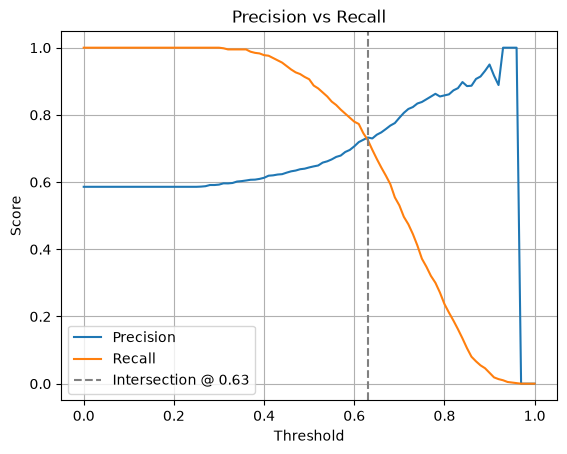

In [12]:
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.axvline(x=best_threshold, color='gray', linestyle='--', label=f'Intersection @ {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall')
plt.legend()
plt.grid(True)
plt.show()

### Answer Q3
ans: **`0.63`**

# Question 4 — F1 Score

F1 combines precision and recall into a single metric:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Compute F1 for all thresholds from 0.0 to 1.0 (step 0.01).  

**At which threshold is F1 maximal?**

In [13]:
f1_scores = []

for p, r in zip(precisions, recalls):
    if p + r == 0:
        f1_scores.append(0)
    else:
        f1 = 2 * p * r / (p + r)
        f1_scores.append(f1)

f1_scores = np.array(f1_scores)

best_f1_idx = np.argmax(f1_scores)
best_f1_threshold = thresholds[best_f1_idx]

print(f"Best F1 threshold: {best_f1_threshold:.2f}")
print(f"Best F1 score:     {f1_scores[best_f1_idx]:.4f}")

Best F1 threshold: 0.41
Best F1 score:     0.7576


### Answer Q4
ans: **`0.41`** (Best F1 ≈ 0.7576)

# Question 5 — 5-Fold Cross Validation

Use `KFold` to evaluate the model on 5 different folds of `df_full_train`.  
Report the **standard deviation** of AUC scores across folds.

**How large is the standard deviation?**

In [14]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

df_full_train_reset = df_full_train.copy()

auc_scores = []

for train_idx, val_idx in kfold.split(df_full_train_reset):
    df_tr = df_full_train_reset.iloc[train_idx]
    df_vl = df_full_train_reset.iloc[val_idx]

    y_tr = df_tr['converted'].values
    y_vl = df_vl['converted'].values

    df_tr = df_tr.drop(columns=['converted'])
    df_vl = df_vl.drop(columns=['converted'])

    train_dicts = df_tr.to_dict(orient='records')
    val_dicts = df_vl.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(train_dicts)
    X_vl = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_tr, y_tr)

    y_pred_fold = model.predict_proba(X_vl)[:, 1]
    auc = roc_auc_score(y_vl, y_pred_fold)
    auc_scores.append(auc)

print(f"AUC scores: {np.round(auc_scores, 4)}")
print(f"Mean AUC:   {np.mean(auc_scores):.4f}")
print(f"Std AUC:    {np.std(auc_scores):.4f}")

AUC scores: [0.7306 0.7296 0.7363 0.7412 0.7209]
Mean AUC:   0.7317
Std AUC:    0.0069


### Answer Q5
ans: **`0.007`** (std ≈ 0.0069)

# Question 6 — Hyperparameter Tuning

Use 5-fold CV to find the best regularization parameter `C`.  
Iterate over `C` values: `[0.000001, 0.001, 1]`.  
Report **mean AUC** and **std** for each value.

**Which `C` leads to the best mean ROC AUC?**

In [15]:
C_values = [0.000001, 0.001, 1]

for C in C_values:
    fold_auc_scores = []

    for train_idx, val_idx in kfold.split(df_full_train_reset):
        df_tr = df_full_train_reset.iloc[train_idx]
        df_vl = df_full_train_reset.iloc[val_idx]

        y_tr = df_tr['converted'].values
        y_vl = df_vl['converted'].values

        df_tr = df_tr.drop(columns=['converted'])
        df_vl = df_vl.drop(columns=['converted'])

        train_dicts = df_tr.to_dict(orient='records')
        val_dicts = df_vl.to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(train_dicts)
        X_vl = dv.transform(val_dicts)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_tr, y_tr)

        y_pred_fold = model.predict_proba(X_vl)[:, 1]
        auc = roc_auc_score(y_vl, y_pred_fold)
        fold_auc_scores.append(auc)

    print(f"C={C} | Mean AUC: {np.mean(fold_auc_scores):.3f} | Std: {np.std(fold_auc_scores):.3f}")

C=1e-06 | Mean AUC: 0.617 | Std: 0.019
C=0.001 | Mean AUC: 0.749 | Std: 0.010
C=1 | Mean AUC: 0.732 | Std: 0.007


### Answer Q6
ans: **`C = 0.001`** (Mean AUC ≈ 0.749)

## Final Answers

### Question 1
ans: **`lead_score`** — highest AUC (≈ 0.7882) as a standalone predictor

### Question 2
ans: Validation AUC **`0.732`**

### Question 3
ans: Precision = Recall at threshold **`0.63`**

### Question 4
ans: F1 is maximal at threshold **`0.41`** (F1 ≈ 0.7576)

### Question 5
ans: Std of AUC across 5 folds **`0.007`**

### Question 6
ans: Best regularization parameter **`C = 0.001`** (Mean AUC ≈ 0.749)